# Verification — kinetic proofreading (Hlavacek et al., 2001; 2002): steady states over a koff dose-response

This notebook checks the steady states of `kinetic_proofreading_hlavacek2001.bngl`, the primary
file, at every point of a 20-point logarithmic grid of the dissociation rate constant
`koff` from 1e-3 to 1 /s. `verify_hlavacek2001.ipynb` is the entry point for the folder; it
checks the time course at `koff = 0.1 /s` and prints the closed form there without asserting
it. This notebook asserts it at all 20 doses.

**The reference is exact.** At steady state the dimer modification chain gives the paper's
closed form for the distribution of dimers over modification states. With
alpha = kp / (kp + 2 koff),

* D_i / D = alpha^i (1 - alpha) for i = 0..4, and D_5 / D = alpha^5,

where D = D_0 + ... + D_5 is the total number of dimers. This is the result the entry-point
notebook prints in its §4 (it cites Eqs. 13–14 of Hlavacek et al. 2002 for it). Derivation:
each D_i (i < 5) is made from D_{i-1} at rate kp (D_0 from crosslinking) and lost at rate
kp + 2 koff, so D_i = alpha D_{i-1}; D_5 is lost only by dissociation, so
D_5 = (kp / 2 koff) D_4 = alpha / (1 - alpha) D_4. Summing gives D = D_0 / (1 - alpha).

The binding part has an exact steady state too, which pins every species, not only the
ratios. Every dimer dissociates at 2 koff whatever its modification state, and a broken dimer
always returns to the unmodified singly bound form, so the aggregation reactions
`L + R <-> B` (forward 2 kon1 L R, reverse koff B) and `B + R <-> D` (forward kon2 B R, reverse
2 koff D) each balance separately at steady state:

* B = a R L with a = 2 kon1 / koff, and D = b R^2 L with b = kon1 kon2 / koff^2.

With the two conservation laws L + B + D = NL and R + B + 2 D = NR this leaves one equation in
the free receptor R,

* g(R) = R + NL (a R + 2 b R^2) / (1 + a R + b R^2) - NR = 0,

which is strictly increasing on (0, NR) and so has exactly one root there. It is solved by
bracketing to machine precision; nothing is integrated.

| | check | reference | tolerance |
|---|---|---|---|
| (a) | D_i / D, i = 0..5, at each of the 20 doses | the closed form above | max rel err 1e-6 |
| (b) | all nine species at each dose | the exact steady state above | max rel err 1e-6 |
| (c) | the BNG2.pl run has reached steady state | its own last two outputs (19000 s and 20000 s) | max rel change 1e-9 |

**Why 1e-6.** The reference has no numerical error of its own beyond the root solve
(~1e-15). BNG2.pl integrates with CVODE at rtol = atol = 1e-10 to t = 20000 s; the slowest
relaxation rate of the network on this grid is ~0.0099 /s (computed below, from the
Jacobian at the exact steady state), so the transient has decayed by e^-198 by then, and the
per-point `.cdat` read here prints 13 significant digits. The tolerance leaves ample headroom
for CVODE's global error, which rtol bounds only per step, and it is 270 times tighter than the worst ratio error of a run stopped at 1000 s (see the last
section), so an unconverged run cannot pass it.

**How BNG2.pl is run.** A temporary copy of the primary file keeps the model block byte for
byte and replaces only the actions block, by one `generate_network` and one `parameter_scan`
over `koff` (`log_scale=>1`, 20 points from 1e-3 to 1, every point started from the seed
state, `t_end=>20000`). The `koff` value of each point is read from the per-point `.net` file
BNG2.pl writes, so the closed form is evaluated at exactly the value that was simulated. Set
`BNGPATH` to a BioNetGen 2.9.3 directory. Nothing here uses any simulator other than BNG2.pl
and its `run_network`.

**Plot convention:** lines = BioNetGen; open markers = the closed form.

In [1]:
import os
import re
import subprocess
import sys
import tempfile
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import brentq

matplotlib.rcParams["figure.dpi"] = 100

STEM = "kinetic_proofreading_hlavacek2001"


def find_model_dir():
    for c in (Path.cwd(), Path.cwd() / "models" / STEM):
        if (c / f"{STEM}.bngl").exists():
            return c.resolve()
    raise FileNotFoundError(f"run this notebook from models/{STEM}/")


MODEL_DIR = find_model_dir()
os.chdir(MODEL_DIR)
REF = Path("reference")
sys.path.insert(0, "../../skills/curate-model/scripts")
from verification_figure import Comparison, residual_axis, summarize, verdict_footer  # noqa: E402

BNG2 = Path(os.path.expanduser(os.environ.get("BNGPATH", "~/Simulations/BioNetGen-2.9.3"))) / "BNG2.pl"
assert BNG2.is_file(), "set BNGPATH to a BioNetGen 2.9.3 directory"

# Tolerances (asserted below; the reasons are in the introduction).
TOL_SS = 1e-6        # (a), (b): BNG2.pl steady state vs the exact steady state
TOL_CONVERGED = 1e-9  # (c): change between the last two outputs of each BNG2.pl run
KOFF_MIN, KOFF_MAX, N_DOSES = 1e-3, 1.0, 20
T_END = 20000.0
N_MOD = 5            # modification steps in the file

## Parameters, read from the file

The closed form needs `NL`, `NR`, `kon1`, `kon2` and `kp`. They are read from the primary
file's parameters block rather than retyped, and `koff` comes from each scan point's `.net`.

In [2]:
model_text = Path(f"{STEM}.bngl").read_text()


def bngl_parameters(text):
    block = re.search(r"^begin parameters\s*$(.*?)^end parameters\s*$", text, re.S | re.M).group(1)
    out = {}
    for line in block.splitlines():
        line = line.split("#", 1)[0].strip()
        if line:
            name, value = line.split(None, 1)
            out[name] = float(value)  # every value in this file is a literal
    return out


P = bngl_parameters(model_text)
NL, NR, KON1, KON2, KP = P["NL"], P["NR"], P["kon1"], P["kon2"], P["kp"]
print({k: P[k] for k in ("NL", "NR", "kon1", "kon2", "koff", "kp")})

{'NL': 602.0, 'NR': 300000.0, 'kon1': 1.661e-08, 'kon2': 3.333e-06, 'koff': 0.1, 'kp': 0.4}


## The exact steady state

In [3]:
SPECIES = ["L", "B", "R", "D0", "D1", "D2", "D3", "D4", "D5"]


def exact_steady_state(koff):
    """[L, B, R, D0..D5] at steady state, from detailed balance of binding + the closed form."""
    a = 2.0 * KON1 / koff
    b = KON1 * KON2 / koff**2

    def g(R):
        return R + NL * (a * R + 2.0 * b * R**2) / (1.0 + a * R + b * R**2) - NR

    R = brentq(g, 0.0, NR, xtol=1e-300, rtol=4 * np.finfo(float).eps, maxiter=500)
    L = NL / (1.0 + a * R + b * R**2)
    B, D = a * R * L, b * R**2 * L
    alpha = KP / (KP + 2.0 * koff)
    Di = [alpha**i * (1.0 - alpha) * D for i in range(N_MOD)] + [alpha**N_MOD * D]
    return np.array([L, B, R, *Di])


def closed_form_ratios(koff):
    alpha = KP / (KP + 2.0 * koff)
    return np.array([alpha**i * (1.0 - alpha) for i in range(N_MOD)] + [alpha**N_MOD])


# The reference must satisfy both conservation laws and make every rate of change vanish.
def mass_action_rhs(y, koff):
    # The network as written in the .bngl rules (and as the entry-point notebook writes it).
    L, B, R, D = y[0], y[1], y[2], y[3:]
    bind, unbind, xlink, dissoc = 2 * KON1 * L * R, koff * B, KON2 * B * R, 2 * koff * D.sum()
    dy = np.zeros(9)
    dy[0] = -bind + unbind
    dy[1] = bind - unbind - xlink + dissoc
    dy[2] = -bind + unbind - xlink + dissoc
    dy[3] = xlink - (2 * koff + KP) * D[0]
    for i in range(1, N_MOD):
        dy[3 + i] = KP * D[i - 1] - (2 * koff + KP) * D[i]
    dy[3 + N_MOD] = KP * D[N_MOD - 1] - 2 * koff * D[N_MOD]
    return dy


for koff in (KOFF_MIN, 0.1, KOFF_MAX):
    y = exact_steady_state(koff)
    gross = 2 * KON1 * y[0] * y[2] + KON2 * y[1] * y[2] + KP * y[3:].sum()
    print(f"koff={koff:<6g} L+B+D-NL={y[0] + y[1] + y[3:].sum() - NL:+.1e}  "
          f"R+B+2D-NR={y[2] + y[1] + 2 * y[3:].sum() - NR:+.1e}  "
          f"max|dy/dt|/gross flux={np.max(np.abs(mass_action_rhs(y, koff))) / gross:.1e}")

koff=0.001  L+B+D-NL=+0.0e+00  R+B+2D-NR=-5.8e-11  max|dy/dt|/gross flux=2.2e-17
koff=0.1    L+B+D-NL=+0.0e+00  R+B+2D-NR=+5.8e-11  max|dy/dt|/gross flux=1.2e-16
koff=1      L+B+D-NL=+0.0e+00  R+B+2D-NR=+0.0e+00  max|dy/dt|/gross flux=2.0e-16


How long BNG2.pl has to integrate: the slowest relaxation rate at each dose is the eigenvalue
of the Jacobian at the exact steady state that is closest to zero, excluding the two zero
eigenvalues that belong to the two conservation laws.

In [4]:
def jacobian(y, koff):
    J = np.zeros((9, 9))
    for j in range(9):
        h = 1e-6 * max(1.0, abs(y[j]))
        e = np.zeros(9)
        e[j] = h
        J[:, j] = (mass_action_rhs(y + e, koff) - mass_action_rhs(y - e, koff)) / (2 * h)
    return J


grid = np.exp(np.linspace(np.log(KOFF_MIN), np.log(KOFF_MAX), N_DOSES))
slowest = []
for koff in grid:
    ev = np.sort(np.linalg.eigvals(jacobian(exact_steady_state(koff), koff)).real)
    assert np.sum(np.abs(ev) < 1e-9) == 2 and np.all(ev < 1e-9)
    slowest.append(ev[ev < -1e-9].max())
lam = max(slowest)
print(f"slowest relaxation rate on the grid: {-lam:.4g} /s (at koff = {grid[np.argmax(slowest)]:.3g}); "
      f"exp(lambda * t_end) = exp({lam * T_END:.0f})")
assert lam * T_END < -100

slowest relaxation rate on the grid: 0.009914 /s (at koff = 0.00207); exp(lambda * t_end) = exp(-198)


## BNG2.pl steady states at 20 doses

In [5]:
head, sep, _ = model_text.rpartition("end model")
assert sep and "begin actions" not in head
ACTIONS = f"""

begin actions
  generate_network({{overwrite=>1}})
  parameter_scan({{method=>"ode",parameter=>"koff",par_min=>{KOFF_MIN},par_max=>{KOFF_MAX},\\
    n_scan_pts=>{N_DOSES},log_scale=>1,t_start=>0,t_end=>{T_END:g},n_steps=>20,\\
    atol=>1e-10,rtol=>1e-10,suffix=>"ss_koff"}})
end actions
"""
check_text = head + sep + ACTIONS
ss_stem = f"{STEM}_sscheck"

with tempfile.TemporaryDirectory(prefix="hlavacek2001_ss_") as tmp:
    tmp = Path(tmp)
    (tmp / f"{ss_stem}.bngl").write_text(check_text)
    run = subprocess.run(["perl", str(BNG2), f"{ss_stem}.bngl"], cwd=tmp,
                         capture_output=True, text=True, timeout=600)
    assert run.returncode == 0, run.stdout[-3000:] + run.stderr[-3000:]
    scan_dir = tmp / f"{ss_stem}_ss_koff"
    koffs, finals, drift = [], [], []
    for k in range(1, N_DOSES + 1):
        point = scan_dir / f"{ss_stem}_ss_koff_{k:05d}"
        net = point.with_suffix(".net").read_text()
        koffs.append(float(re.search(r"^\s*\d+\s+koff\s+(\S+)", net, re.M).group(1)))
        cdat = np.loadtxt(point.with_suffix(".cdat"))
        assert np.isclose(cdat[-1, 0], T_END)
        finals.append(cdat[-1, 1:])
        drift.append(np.max(np.abs(cdat[-1, 1:] - cdat[-2, 1:]) /
                            np.maximum(np.abs(cdat[-1, 1:]), 1e-300)))
    species_block = re.search(r"begin species(.*?)end species",
                              (tmp / f"{ss_stem}.net").read_text(), re.S).group(1)
    net_species = [ln.split()[1] for ln in species_block.strip().splitlines()]

koffs, finals, drift = np.array(koffs), np.array(finals), np.array(drift)
print(f"{len(koffs)} doses, koff = {koffs[0]:.6g} .. {koffs[-1]:.6g} /s")
print("BNG2.pl species order:")
for i, s in enumerate(net_species, 1):
    print(f"  {i}  {s}")

20 doses, koff = 0.001 .. 1 /s
BNG2.pl species order:
  1  L(mod~0,r,r)
  2  R(l)
  3  L(mod~0,r!1,r).R(l!1)
  4  L(mod~0,r!1,r!2).R(l!1).R(l!2)
  5  L(mod~1,r!1,r!2).R(l!1).R(l!2)
  6  L(mod~2,r!1,r!2).R(l!1).R(l!2)
  7  L(mod~3,r!1,r!2).R(l!1).R(l!2)
  8  L(mod~4,r!1,r!2).R(l!1).R(l!2)
  9  L(mod~5,r!1,r!2).R(l!1).R(l!2)


The `.cdat` columns are the nine species in the `.net` order printed above. They are mapped
onto [L, B, R, D0..D5] by their BNGL strings, not by position.

In [6]:
WANT = {
    "L": "L(mod~0,r,r)",
    "R": "R(l)",
    "B": "L(mod~0,r!1,r).R(l!1)",
    **{f"D{i}": f"L(mod~{i},r!1,r!2).R(l!1).R(l!2)" for i in range(N_MOD + 1)},
}
order = [net_species.index(WANT[s]) for s in SPECIES]
bng = finals[:, order]
exact = np.array([exact_steady_state(k) for k in koffs])

assert np.all(np.diff(np.log(koffs)) > 0)
assert np.allclose(np.log(koffs), np.linspace(np.log(KOFF_MIN), np.log(KOFF_MAX), N_DOSES), atol=1e-12)

# (c) converged
print(f"(c) max relative change between t = {T_END - 1000:g} s and {T_END:g} s: {drift.max():.2e} "
      f"(tol {TOL_CONVERGED:g})")
assert drift.max() <= TOL_CONVERGED

# (a) dimer distribution
bng_ratio = bng[:, 3:] / bng[:, 3:].sum(axis=1, keepdims=True)
ref_ratio = np.array([closed_form_ratios(k) for k in koffs])
err_ratio = np.abs(bng_ratio - ref_ratio) / ref_ratio
print(f"(a) D_i/D vs alpha^i (1 - alpha), alpha^5: max rel err {err_ratio.max():.2e} "
      f"(tol {TOL_SS:g}) over {err_ratio.size} values")
assert err_ratio.max() <= TOL_SS

# (b) every species
err_species = np.abs(bng - exact) / np.abs(exact)
print(f"(b) all nine species vs the exact steady state: max rel err {err_species.max():.2e} "
      f"(tol {TOL_SS:g}) over {err_species.size} values")
assert err_species.max() <= TOL_SS

print()
print(f"{'koff /s':>11} {'alpha':>9} {'D5/D BNG':>12} {'alpha^5':>12} {'rel err':>9} "
      f"{'worst species':>14} {'rel err':>9}")
for k, koff in enumerate(koffs):
    alpha = KP / (KP + 2 * koff)
    w = int(np.argmax(err_species[k]))
    print(f"{koff:11.5g} {alpha:9.6f} {bng_ratio[k, 5]:12.9f} {alpha**5:12.9f} "
          f"{err_ratio[k, 5]:9.1e} {SPECIES[w]:>14} {err_species[k, w]:9.1e}")

(c) max relative change between t = 19000 s and 20000 s: 9.94e-12 (tol 1e-09)
(a) D_i/D vs alpha^i (1 - alpha), alpha^5: max rel err 4.14e-12 (tol 1e-06) over 120 values
(b) all nine species vs the exact steady state: max rel err 2.86e-11 (tol 1e-06) over 180 values

    koff /s     alpha     D5/D BNG      alpha^5   rel err  worst species   rel err
      0.001  0.995025  0.975370668  0.975370668   8.0e-16              L   2.9e-11
  0.0014384  0.992859  0.964801843  0.964801843   1.6e-15              L   1.3e-12
  0.0020691  0.989760  0.949839078  0.949839078   5.8e-16              B   9.9e-14
  0.0029764  0.985336  0.928801205  0.928801205   2.6e-15              L   1.0e-12
  0.0042813  0.979042  0.899511188  0.899511188   7.7e-15              L   1.8e-12
  0.0061585  0.970127  0.859298272  0.859298272   1.3e-15              L   2.7e-12
  0.0088587  0.957585  0.805169767  0.805169767   6.3e-15              L   6.3e-13
   0.012743  0.940103  0.734304409  0.734304409   1.2e-14           

## The committed protocol stops at 1000 s, before steady state at low koff

The file's own `parameter_scan` (30 points, `koff` 1e-3 to 1, `t_end => 1000`) is described in
its `#@protocol:` as showing the steady-state fraction of terminally modified dimers. At the low
end of the grid 1000 s is not long enough: the network relaxes at ~0.0099 /s there, and free
ligand, which the scan reports as 0.15 molecules at koff = 1e-3, is still 24% away from its
steady state. The committed `reference/` scan is compared with the exact steady state below.
This is reported, not asserted, and the committed file is not changed: its scan still shows
the proofreading trend correctly, D_5/D being within 2.7e-4 of alpha^5 at every point.

In [7]:
committed = np.loadtxt(REF / f"{STEM}_scan_koff.scan")
hdr = (REF / f"{STEM}_scan_koff.scan").read_text().splitlines()[0].lstrip("#").split()
col = {name: hdr.index(name) for name in hdr}
c_koff = committed[:, 0]
c_species = np.column_stack(
    [committed[:, col["Obs_Free_L"]], committed[:, col["Obs_Singly_Bound"]],
     committed[:, col["Obs_Free_R"]]] + [committed[:, col[f"Obs_D{i}"]] for i in range(N_MOD + 1)]
)
c_exact = np.array([exact_steady_state(k) for k in c_koff])
c_err = np.abs(c_species - c_exact) / np.abs(c_exact)
c_ratio = c_species[:, 3:] / committed[:, [col["Obs_Tot_Dimers"]]]
c_ratio_err = np.abs(c_ratio - np.array([closed_form_ratios(k) for k in c_koff])) / np.array(
    [closed_form_ratios(k) for k in c_koff])
print(f"{'koff /s':>11} {'worst species':>14} {'rel err':>9} {'D_i/D rel err':>14}")
for k in range(len(c_koff)):
    w = int(np.argmax(c_err[k]))
    print(f"{c_koff[k]:11.5g} {SPECIES[w]:>14} {c_err[k, w]:9.2e} {c_ratio_err[k].max():14.2e}")
late = c_koff >= 0.07
print(f"\ncommitted scan, koff >= 0.07 /s: max rel err {c_err[late].max():.1e} (at steady state); "
      f"koff = 1e-3: {c_err[0].max():.2f} (free ligand), D_i/D {c_ratio_err[0].max():.1e}")

    koff /s  worst species   rel err  D_i/D rel err
      0.001              L  2.43e-01       2.72e-04
   0.001269              L  1.51e-01       2.13e-04
  0.0016103              L  9.41e-02       1.67e-04
  0.0020434              L  5.86e-02       1.30e-04
  0.0025929              L  3.64e-02       1.01e-04
  0.0032903              L  2.26e-02       7.82e-05
  0.0041753              L  1.40e-02       6.00e-05
  0.0052983              L  8.63e-03       4.58e-05
  0.0067234              L  5.26e-03       3.52e-05
  0.0085317              L  3.16e-03       2.66e-05
   0.010826              L  1.85e-03       1.95e-05
   0.013738              L  1.03e-03       1.37e-05
   0.017433              L  5.36e-04       8.99e-06
   0.022122              L  2.47e-04       5.26e-06
   0.028072              L  9.46e-05       2.58e-06
   0.035622              L  2.70e-05       9.53e-07
   0.045204              L  4.86e-06       2.75e-07
   0.057362              L  4.36e-07       4.37e-08
    0.07279 

## Verification figure

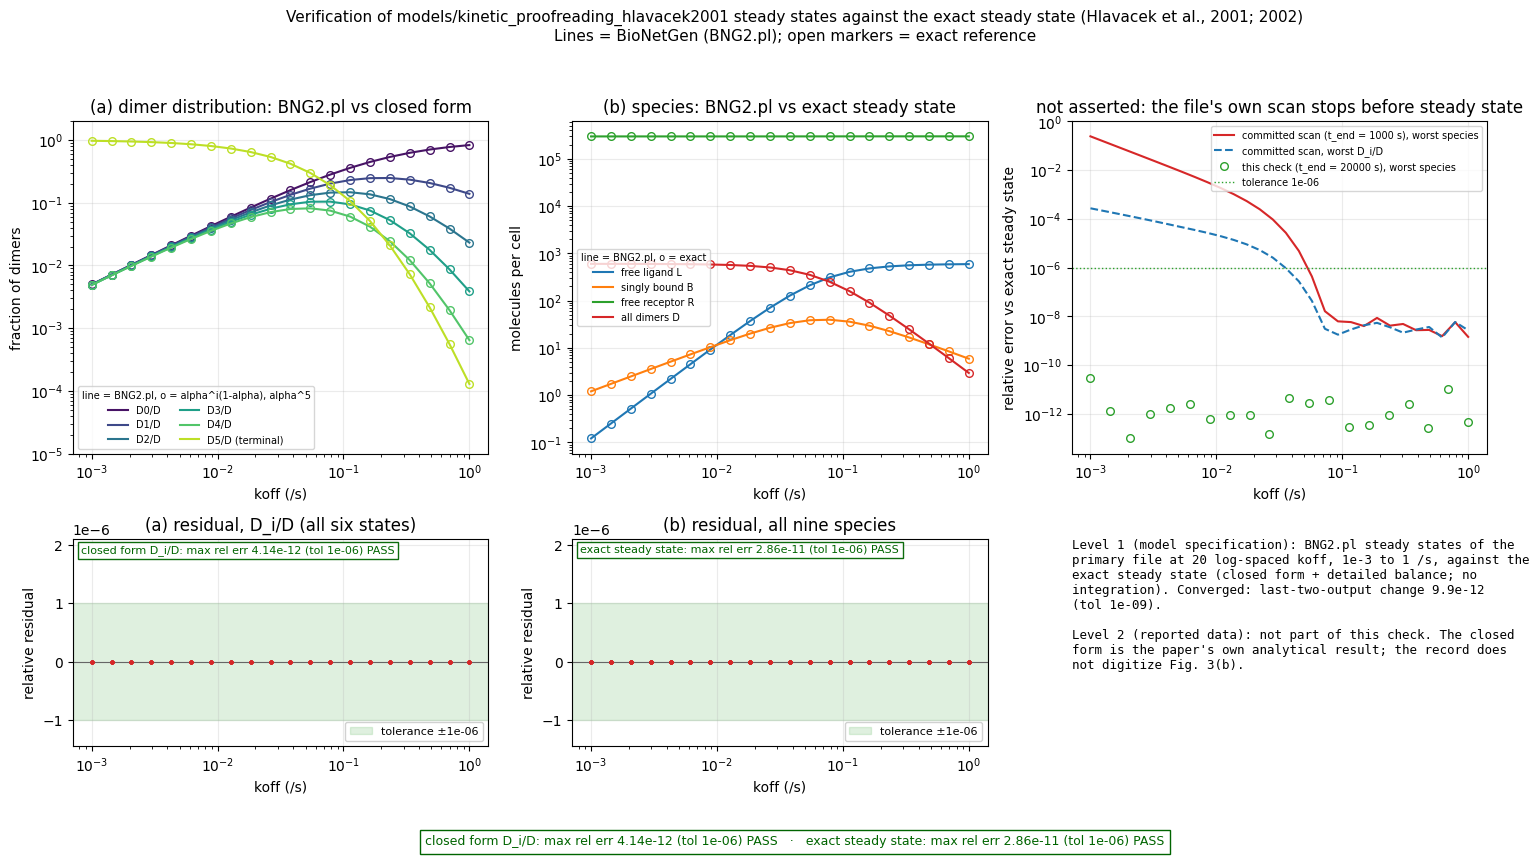

closed form D_i/D: max rel err 4.14e-12 (tol 1e-06) PASS
exact steady state: max rel err 2.86e-11 (tol 1e-06) PASS


In [8]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8.6), gridspec_kw={"height_ratios": [1.6, 1.0]})
colors = plt.cm.viridis(np.linspace(0.05, 0.9, N_MOD + 1))

ax = axes[0, 0]
for i in range(N_MOD + 1):
    ax.plot(koffs, bng_ratio[:, i], "-", color=colors[i], lw=1.5,
            label=f"D{i}/D" if i < N_MOD else "D5/D (terminal)")
    ax.plot(koffs, ref_ratio[:, i], "o", mfc="none", mec=colors[i], ms=5.5, ls="none")
ax.set(xscale="log", yscale="log", xlabel="koff (/s)", ylabel="fraction of dimers",
       title="(a) dimer distribution: BNG2.pl vs closed form", ylim=(1e-5, 2))
ax.legend(fontsize=7, ncol=2, title="line = BNG2.pl, o = alpha^i(1-alpha), alpha^5",
          title_fontsize=7, loc="lower left")
ax.grid(alpha=0.25)

ax = axes[0, 1]
labels = {"L": "free ligand L", "B": "singly bound B", "R": "free receptor R"}
for j, (s, c) in enumerate(zip(["L", "B", "R"], ["C0", "C1", "C2"])):
    ax.plot(koffs, bng[:, j], "-", color=c, lw=1.5, label=labels[s])
    ax.plot(koffs, exact[:, j], "o", mfc="none", mec=c, ms=5.5, ls="none")
ax.plot(koffs, bng[:, 3:].sum(1), "-", color="C3", lw=1.5, label="all dimers D")
ax.plot(koffs, exact[:, 3:].sum(1), "o", mfc="none", mec="C3", ms=5.5, ls="none")
ax.set(xscale="log", yscale="log", xlabel="koff (/s)", ylabel="molecules per cell",
       title="(b) species: BNG2.pl vs exact steady state")
ax.legend(fontsize=7, loc="center left", title="line = BNG2.pl, o = exact", title_fontsize=7)
ax.grid(alpha=0.25)

ax = axes[0, 2]
ax.semilogx(c_koff, c_err.max(1), "-", color="C3", lw=1.5,
            label="committed scan (t_end = 1000 s), worst species")
ax.semilogx(c_koff, c_ratio_err.max(1), "--", color="C0", lw=1.5,
            label="committed scan, worst D_i/D")
ax.semilogx(koffs, err_species.max(1), "o", mfc="none", mec="C2", ms=5.5, ls="none",
            label="this check (t_end = 20000 s), worst species")
ax.axhline(TOL_SS, color="tab:green", lw=1, ls=":", label=f"tolerance {TOL_SS:g}")
ax.set(yscale="log", xlabel="koff (/s)", ylabel="relative error vs exact steady state",
       title="not asserted: the file's own scan stops before steady state")
ax.legend(fontsize=7, loc="upper right")
ax.grid(alpha=0.25)

flat_k = np.repeat(koffs, N_MOD + 1)
metrics = []
comp_a = Comparison("closed form D_i/D", ref_ratio.ravel(), tol=TOL_SS, floor=1e-300)
residual_axis(axes[1, 0], flat_k, bng_ratio.ravel(), comp_a, xlabel="koff (/s)",
              title="(a) residual, D_i/D (all six states)")
axes[1, 0].set_xscale("log")
metrics.append(summarize(flat_k, bng_ratio.ravel(), comp_a))

flat_k9 = np.repeat(koffs, len(SPECIES))
comp_b = Comparison("exact steady state", exact.ravel(), tol=TOL_SS, floor=1e-300)
residual_axis(axes[1, 1], flat_k9, bng.ravel(), comp_b, xlabel="koff (/s)",
              title="(b) residual, all nine species")
axes[1, 1].set_xscale("log")
metrics.append(summarize(flat_k9, bng.ravel(), comp_b))

ax = axes[1, 2]
ax.axis("off")
ax.text(0.0, 1.0,
        "Level 1 (model specification): BNG2.pl steady states of the\n"
        "primary file at 20 log-spaced koff, 1e-3 to 1 /s, against the\n"
        "exact steady state (closed form + detailed balance; no\n"
        "integration). Converged: last-two-output change "
        f"{drift.max():.1e}\n(tol {TOL_CONVERGED:g}).\n\n"
        "Level 2 (reported data): not part of this check. The closed\n"
        "form is the paper's own analytical result; the record does\n"
        "not digitize Fig. 3(b).",
        va="top", fontsize=9, family="monospace")

fig.suptitle("Verification of models/kinetic_proofreading_hlavacek2001 steady states "
             "against the exact steady state (Hlavacek et al., 2001; 2002)\n"
             "Lines = BioNetGen (BNG2.pl); open markers = exact reference", fontsize=11)
fig.tight_layout(rect=(0, 0.05, 1, 0.95))
ok = verdict_footer(fig, metrics)
assert ok
fig.savefig("verify_hlavacek2001_steady_state.png", dpi=150, bbox_inches="tight")
plt.show()
for m in metrics:
    print(m.line())